In [25]:
import numpy as np
import pandas as pd
import pymc as pm
import arviz as az
import matplotlib.pyplot as plt
import seaborn as sns
import arviz.labels as azl

# Data Preprocessing

In [2]:
data = pd.read_csv("sf_covid19_cases.csv")
data

,specimen_collection_date,characteristic_type,characteristic_group,characteristic_group_sort_order,population_estimate,new_cases,cumulative_cases,data_as_of,data_loaded_at
0,2022 Oct 12 12:00:00 AM,Age Group,0-4,1,"39,354",5,"6,583",2023 Sep 11 04:30:00 AM,2023 Sep 11 09:44:34 AM
1,2023 Mar 31 12:00:00 AM,Age Group,0-4,1,"39,354",2,"7,201",2023 Sep 11 04:30:00 AM,2023 Sep 11 09:44:34 AM
2,2023 Apr 01 12:00:00 AM,Age Group,0-4,1,"39,354",3,"7,204",2023 Sep 11 04:30:00 AM,2023 Sep 11 09:44:34 AM
3,2023 Apr 02 12:00:00 AM,Age Group,0-4,1,"39,354",1,"7,205",2023 Sep 11 04:30:00 AM,2023 Sep 11 09:44:34 AM
4,2023 Apr 03 12:00:00 AM,Age Group,0-4,1,"39,354",0,"7,205",2023 Sep 11 04:30:00 AM,2023 Sep 11 09:44:34 AM
...,...,...,...,...,...,...,...,...,...
57855,2022 Feb 05 12:00:00 AM,Transmission Type,Unknown,3,NaN,179,"70,377",2023 Jun 06 04:30:11 AM,2023 Sep 11 09:44:40 AM
57856,2022 Feb 06 12:00:00 AM,Transmission Type,Unknown,3,NaN,133,"70,510",2023 Jun 06 04:30:11 AM,2023 Sep 11 09:44:40 AM
57857,2022 Feb 07 12:00:00 AM,Transmission Type,Unknown,3,NaN,306,"70,816",2023 Jun 06 04:30:11 AM,2023 Sep 11 09:44:40 AM
57858,2022 Feb 08 12:00:00 AM,Transmission Type,Unknown,3,NaN,275,"71,091",2023 Jun 06 04:30:11 AM,2023 Sep 11 09:44:40 AM


In [3]:
# Data filtering
race_data = data.loc[(data["characteristic_type"] == "Race/Ethnicity") &
                     (data["characteristic_group"] != "Unknown") &
                     (data["characteristic_group"] != "Other") &
                     (data["characteristic_group"] != "Multi-racial"),
    ["specimen_collection_date",
     "characteristic_group",
     "population_estimate",
     "new_cases",
     "cumulative_cases"]
]
# Data typing
race_data['specimen_collection_date'] = pd.to_datetime(race_data['specimen_collection_date'])
race_data['population_estimate'] = race_data['population_estimate'].str.replace(',', '').astype(float)
race_data['new_cases'] = race_data['new_cases'].str.replace(',', '').astype(float)
race_data['cumulative_cases'] = race_data['cumulative_cases'].str.replace(',', '').astype(float)
race_data.fillna(0)
race_data

/var/folders/r_/94kdvsqs2k5cv76z0tm57cq80000gn/T/ipykernel_7931/899493283.py:13: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  race_data['specimen_collection_date'] = pd.to_datetime(race_data['specimen_collection_date'])


,specimen_collection_date,characteristic_group,population_estimate,new_cases,cumulative_cases
30202,2023-04-08,American Indian or Alaska Native,1796.0,0.0,450.0
30203,2023-04-09,American Indian or Alaska Native,1796.0,0.0,450.0
30204,2023-04-10,American Indian or Alaska Native,1796.0,1.0,451.0
30205,2023-04-11,American Indian or Alaska Native,1796.0,0.0,451.0
30206,2023-04-12,American Indian or Alaska Native,1796.0,1.0,452.0
...,...,...,...,...,...
37895,2022-02-27,White,348449.0,14.0,29377.0
37896,2022-02-28,White,348449.0,32.0,29409.0
37897,2022-03-01,White,348449.0,44.0,29453.0
37898,2022-03-02,White,348449.0,31.0,29484.0


In [4]:
def aggregate_date_by_week(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()
    # Aggregate data by group, year-week
    df['year_week'] = df['specimen_collection_date'].dt.strftime('%Y-%U')
    aggregated_data = df.groupby(["characteristic_group", "year_week"]).agg(
        specimen_collection_date=("specimen_collection_date", "first"),
        population_estimate=("population_estimate", "first"),
        new_cases=("new_cases", "sum"),
        cumulative_cases=("cumulative_cases", "first")
    )

    assert (aggregated_data["population_estimate"] > 0).all()

    return aggregated_data.fillna(0)

In [5]:
aggregated_data = aggregate_date_by_week(race_data)
aggregated_data["new_cases_per_pop"] = aggregated_data["new_cases"] / aggregated_data["population_estimate"]
aggregated_data["cumulative_cases_per_pop"] = aggregated_data["cumulative_cases"] / aggregated_data["population_estimate"]
aggregated_data

specimen_collection_date  \
characteristic_group             year_week                            
American Indian or Alaska Native 2020-09                 2020-03-07   
                                 2020-10                 2020-03-14   
                                 2020-11                 2020-03-21   
                                 2020-12                 2020-03-28   
                                 2020-13                 2020-04-04   
...                                                             ...   
White                            2023-32                 2023-08-06   
                                 2023-33                 2023-08-13   
                                 2023-34                 2023-08-20   
                                 2023-35                 2023-08-27   
                                 2023-36                 2023-09-03   

                                            population_estimate  new_cases  \
characteristic_group             year_week                                   
American Indian or Alaska Native 2020-09                 1796.0        0.0   
                                 2020-10                 1796.0        0.0   
                                 2020-11                 1796.0        0.0   
                                 2020-12                 1796.0        0.0   
                                 2020-13                 1796.0        0.0   
...                                                         ...        ...   
White                            2023-32               348449.0       77.0   
                                 2023-33               348449.0       81.0   
                                 2023-34               348449.0       92.0   
                                 2023-35               348449.0       92.0   
                                 2023-36               348449.0       55.0   

                                            cumulative_cases  \
characteristic_group             year_week                     
American Indian or Alaska Native 2020-09                 0.0   
                                 2020-10                 0.0   
                                 2020-11                 0.0   
                                 2020-12                 0.0   
                                 2020-13                 0.0   
...                                                      ...   
White                            2023-32             48872.0   
                                 2023-33             48950.0   
                                 2023-34             49031.0   
                                 2023-35             49126.0   
                                 2023-36             49223.0   

                                            new_cases_per_pop  \
characteristic_group             year_week                      
American Indian or Alaska Native 2020-09             0.000000   
                                 2020-10             0.000000   
                                 2020-11             0.000000   
                                 2020-12             0.000000   
                                 2020-13             0.000000   
...                                                       ...   
White                            2023-32             0.000221   
                                 2023-33             0.000232   
                                 2023-34             0.000264   
                                 2023-35             0.000264   
                                 2023-36             0.000158   

                                            cumulative_cases_per_pop  
characteristic_group             year_week                            
American Indian or Alaska Native 2020-09                    0.000000  
                                 2020-10                    0.000000  
                                 2020-11                    0.000000  
                                 2020-12                    0.000000  

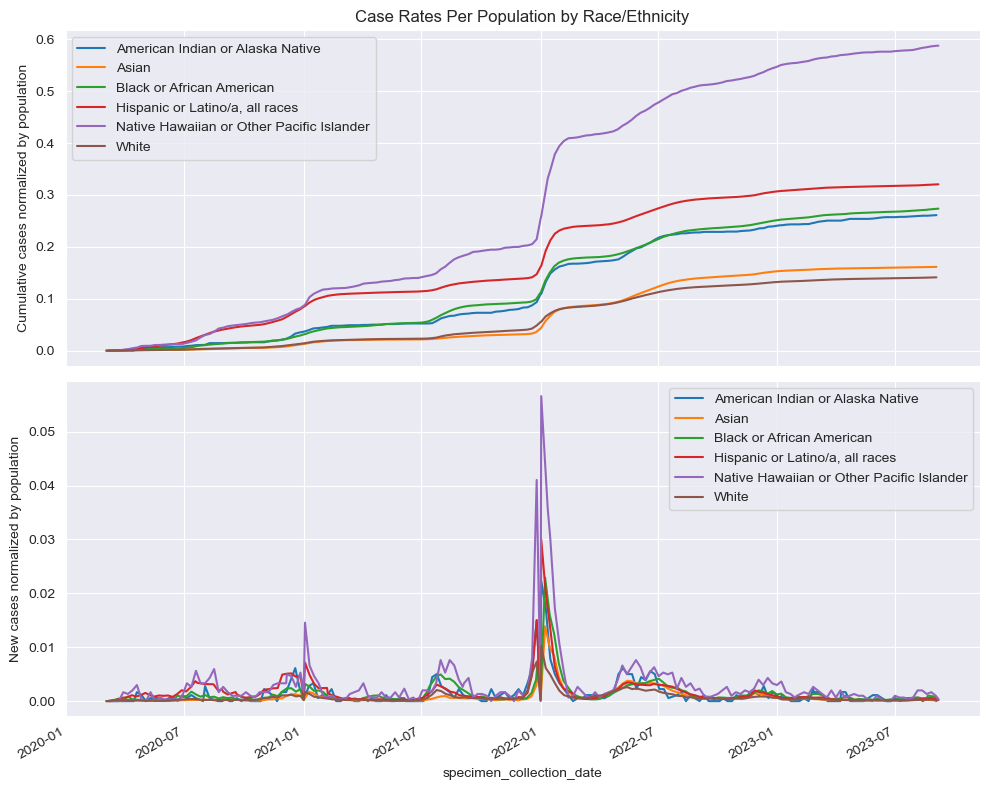

In [7]:
fig, (ax0, ax1) = plt.subplots(2, 1, figsize=(10, 8), sharex=True)

for name, group in aggregated_data.groupby("characteristic_group"):
    group = group.sort_values("specimen_collection_date")
    group.plot(
        kind='line',
        x="specimen_collection_date",
        y="cumulative_cases_per_pop",
        ax=ax0,
        label=name
    )

ax0.set_ylabel("Cumulative cases normalized by population")

for name, group in aggregated_data.groupby("characteristic_group"):
    group = group.sort_values("specimen_collection_date")
    group.plot(
        kind='line',
        x="specimen_collection_date",
        y="new_cases_per_pop",
        ax=ax1,
        label=name
    )

ax1.set_ylabel("New cases normalized by population")
ax0.set_xlabel("Date")

ax0.set_title("Case Rates Per Population by Race/Ethnicity")
plt.legend()
plt.tight_layout()
plt.show()

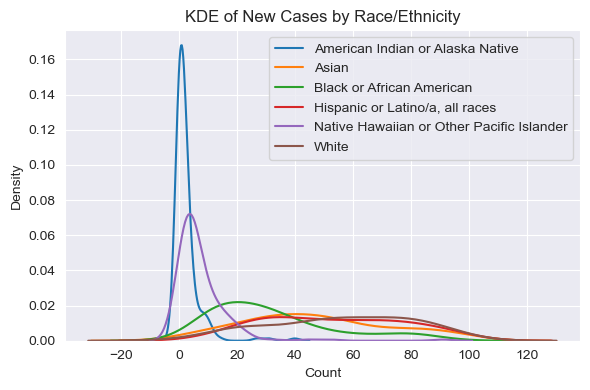

In [8]:
fig, ax = plt.subplots(1, 1, figsize=(6, 4), sharex=True)

for name, group in aggregated_data.groupby("characteristic_group"):
    group = group.sort_values("specimen_collection_date")
    sns.kdeplot(group.loc[group["new_cases"] < 100, "new_cases"], ax=ax, label=name)

ax.set_xlabel("Count")

ax.set_title("KDE of New Cases by Race/Ethnicity")
plt.legend()
plt.tight_layout()
plt.show()

# NB Base Model

In [6]:
groups = aggregated_data.index.get_level_values("characteristic_group").unique()
weeks  = aggregated_data.index.get_level_values("year_week").unique()
pop = aggregated_data["population_estimate"].to_numpy()
pop_scaled = pop / pop.mean()
y = aggregated_data["new_cases"].to_numpy()

num_groups = len(groups)
T = len(weeks)

group_map = {g: i for i, g in enumerate(groups)}
week_map  = {w: i for i, w in enumerate(weeks)}

aggregated_data["group_idx"] = aggregated_data.index.get_level_values("characteristic_group").map(group_map)
aggregated_data["week_idx"]  = aggregated_data.index.get_level_values("year_week").map(week_map)
group_idx = aggregated_data["group_idx"].to_numpy()
week_idx  = aggregated_data["week_idx"].to_numpy()

coords = {
    "group": groups,
    "week": weeks,
    "obs": np.arange(len(aggregated_data))
}

In [7]:
from itertools import combinations

def contrasts(var, index):
    """Calculate differences between levels with names like "alpha[low] - alpha[high]".

    var: pytensor.tensor.var.TensorVariable
    index: pandas.Index
    """
    name = var.name
    for i, j in combinations(range(index.size), 2):
        a, b = index[i], index[j]
        pm.Deterministic(f"{name}[{a}] - {name}[{b}]", var[i] - var[j])

In [8]:
with pm.Model(coords=coords) as m1:
    group_idx_data = pm.Data("group_idx", group_idx, dims="obs")
    week_idx_data = pm.Data("week_idx", week_idx, dims="obs")
    pop_data = pm.Data("population", pop_scaled, dims="obs")
    y_data = pm.Data("y", y, dims="obs")

    # Priors
    sigma_a = pm.HalfNormal("sigma_a", sigma=1.0)
    sigma_f = pm.HalfNormal("sigma_f", sigma=1.0)
    a = pm.ZeroSumNormal("a", sigma=sigma_a, dims="group")
    f = pm.GaussianRandomWalk("f", sigma=sigma_f, dims="week")

    phi = pm.HalfNormal("phi", sigma=1)

    # Linear predictor
    log_mu = a[group_idx_data] + f[week_idx_data]
    mu = pm.Deterministic("mu", pop_data * pm.math.exp(log_mu), dims="obs")

    contrasts(a, coords["group"])

    # Likelihood
    y_obs = pm.NegativeBinomial("y_obs", mu=mu, alpha=phi, observed=y_data)
    trace = pm.sample(5000, tune=1000, target_accept=0.90)
    ppc = pm.sample_posterior_predictive(trace)
    pm.compute_log_likelihood(trace)

/Users/keithhall/miniforge3/envs/pymc-env/lib/python3.12/site-packages/pymc/distributions/timeseries.py:290: UserWarning: Initial distribution not specified, defaulting to `Normal.dist(0, 100)`.You can specify an init_dist manually to suppress this warning.
  warnings.warn(
Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [sigma_a, sigma_f, a, f, phi]


Output()

Sampling 4 chains for 1_000 tune and 5_000 draw iterations (4_000 + 20_000 draws total) took 27 seconds.
Sampling: [y_obs]


Output()

Output()

In [57]:
az.summary(trace, var_names=["a", "f"], filter_vars="like")

,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
f[2020-09],1.406,0.303,0.831,1.964,0.002,0.002,29107.0,17313.0,1.0
f[2020-10],2.045,0.236,1.598,2.486,0.001,0.002,32455.0,16525.0,1.0
f[2020-11],3.218,0.182,2.880,3.564,0.001,0.001,38856.0,15937.0,1.0
f[2020-12],3.703,0.181,3.367,4.043,0.001,0.001,35886.0,15001.0,1.0
f[2020-13],3.905,0.187,3.550,4.259,0.001,0.001,35853.0,15388.0,1.0
...,...,...,...,...,...,...,...,...,...
a[Black or African American] - a[Native Hawaiian or Other Pacific Islander],-0.701,0.060,-0.811,-0.588,0.000,0.000,41712.0,14144.0,1.0
a[Black or African American] - a[White],0.709,0.051,0.613,0.802,0.000,0.000,42703.0,15790.0,1.0
"a[Hispanic or Latino/a, all races] - a[Native Hawaiian or Other Pacific Islander]",-0.533,0.059,-0.646,-0.424,0.000,0.000,35794.0,15069.0,1.0
"a[Hispanic or Latino/a, all races] - a[White]",0.877,0.050,0.779,0.968,0.000,0.000,36074.0,15694.0,1.0


In [9]:
obs_var = y.var()
ppc_var = ppc.posterior_predictive["y_obs"].var(("chain","draw")).mean().item()

print("Observed variance:", obs_var)
print("Posterior predictive variance:", ppc_var)

Observed variance: 111174.38064371607
Posterior predictive variance: 24215.156974809943


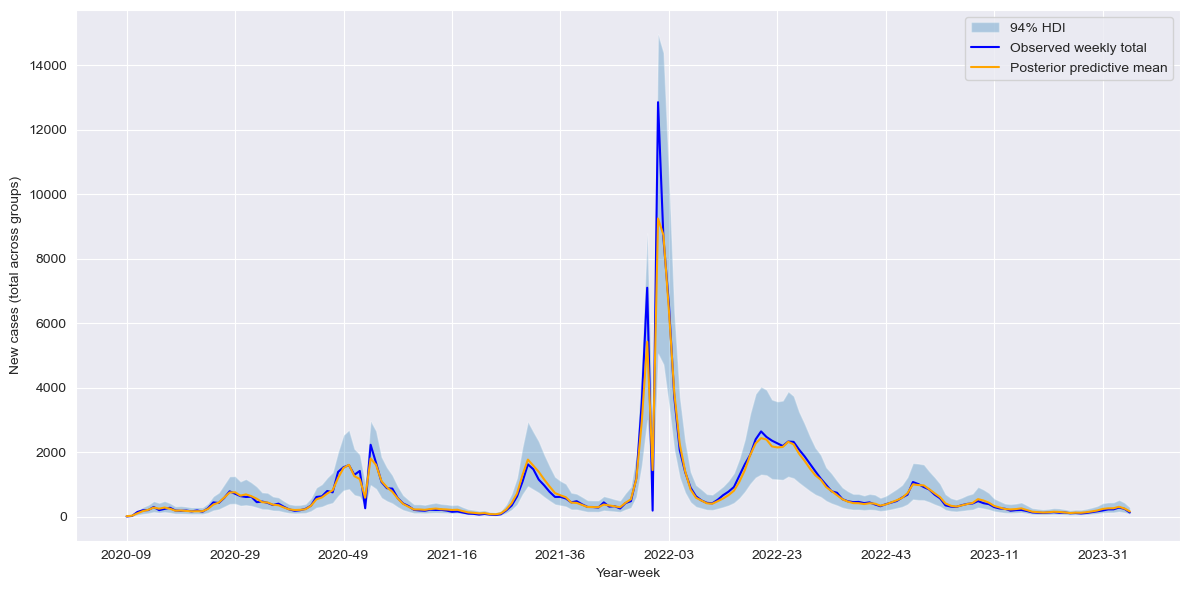

In [59]:
y_sim = ppc.posterior_predictive["y_obs"].stack(sample=("chain", "draw")).values

y_ppc_weekly = np.zeros((T, y_sim.shape[1]))
for t in range(T):
    mask = (week_idx == t)
    y_ppc_weekly[t, :] = y_sim[mask].sum(axis=0)

y_weekly_obs = aggregated_data.groupby("week_idx")["new_cases"].sum().values

y_mean = y_ppc_weekly.mean(axis=1)
lower = np.percentile(y_ppc_weekly, 3, axis=1)
upper = np.percentile(y_ppc_weekly, 97, axis=1)

plt.figure(figsize=(12,6))
plt.fill_between(weeks, lower, upper, alpha=0.3, label="94% HDI")
plt.plot(weeks, y_weekly_obs, label="Observed weekly total", color="blue")
plt.plot(weeks, y_mean, label="Posterior predictive mean", color="orange")

plt.xticks(
    ticks=weeks[::20],
    labels=weeks[::20],
)
plt.xlabel("Year-week")
plt.ylabel("New cases (total across groups)")
plt.legend()
plt.tight_layout()
plt.show()

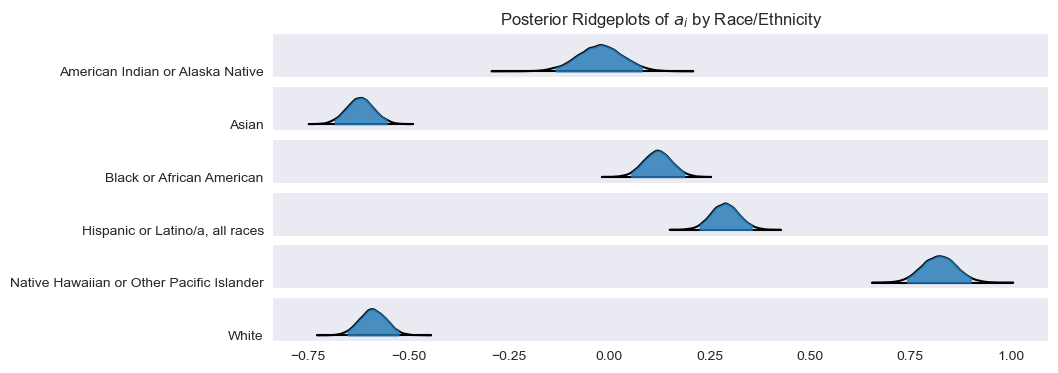

In [60]:
fig, axes = plt.subplots(nrows=num_groups, ncols=1, figsize=(10, 4), sharex=True)

for i, group in enumerate(groups):
    az.plot_forest(
        trace,
        var_names=["a"],
        coords={"group": [group]},
        kind="ridgeplot",
        ridgeplot_truncate=False,
        ridgeplot_alpha=0.8,
        combined=True,
        ax=axes[i],
        labeller=azl.MapLabeller(var_name_map={"a": group})
    )

axes[0].set_title(r"Posterior Ridgeplots of $a_i$ by Race/Ethnicity")
plt.show()

# LOO Comparison of with ZINB and Poisson Models

In [61]:
with pm.Model(coords=coords) as m2:
    group_idx_data = pm.Data("group_idx", group_idx, dims="obs")
    week_idx_data = pm.Data("week_idx", week_idx, dims="obs")
    pop_data = pm.Data("population", pop_scaled, dims="obs")
    y_data = pm.Data("y", y, dims="obs")

    # Priors
    sigma_a = pm.HalfNormal("sigma_a", sigma=1.0)
    sigma_f = pm.HalfNormal("sigma_f", sigma=1.0)
    a = pm.ZeroSumNormal("a", sigma=sigma_a, dims="group")
    f = pm.GaussianRandomWalk("f", sigma=sigma_f, dims="week")
    psi = pm.Beta("psi", alpha=10, beta=1)

    phi = pm.HalfNormal("phi", sigma=1)

    # Linear predictor
    log_mu = a[group_idx_data] + f[week_idx_data]
    mu = pm.Deterministic("mu", pop_data * pm.math.exp(log_mu), dims="obs")

    contrasts(a, coords["group"])

    # Likelihood
    y_obs = pm.ZeroInflatedNegativeBinomial("y_obs", psi=psi, mu=mu, alpha=phi, observed=y_data)
    trace2 = pm.sample(5000, tune=1000, target_accept=0.90)
    ppc = pm.sample_posterior_predictive(trace2)
    pm.compute_log_likelihood(trace2)

/Users/keithhall/miniforge3/envs/pymc-env/lib/python3.12/site-packages/pymc/distributions/timeseries.py:290: UserWarning: Initial distribution not specified, defaulting to `Normal.dist(0, 100)`.You can specify an init_dist manually to suppress this warning.
  warnings.warn(
Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [sigma_a, sigma_f, a, f, psi, phi]


Output()

Sampling 4 chains for 1_000 tune and 5_000 draw iterations (4_000 + 20_000 draws total) took 26 seconds.
Sampling: [y_obs]


Output()

Output()

In [62]:
az.summary(trace2, var_names=["a", "f", "psi"], filter_vars="like")

,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
f[2020-09],1.496,0.334,0.878,2.138,0.002,0.002,22057.0,14547.0,1.0
f[2020-10],2.083,0.242,1.635,2.547,0.002,0.002,26055.0,16038.0,1.0
f[2020-11],3.216,0.181,2.881,3.559,0.001,0.001,34455.0,16112.0,1.0
f[2020-12],3.698,0.180,3.364,4.035,0.001,0.001,39164.0,16154.0,1.0
f[2020-13],3.905,0.185,3.577,4.273,0.001,0.001,33931.0,15563.0,1.0
...,...,...,...,...,...,...,...,...,...
a[Black or African American] - a[Native Hawaiian or Other Pacific Islander],-0.708,0.060,-0.821,-0.593,0.000,0.000,36239.0,15502.0,1.0
a[Black or African American] - a[White],0.709,0.052,0.616,0.811,0.000,0.000,41963.0,14991.0,1.0
"a[Hispanic or Latino/a, all races] - a[Native Hawaiian or Other Pacific Islander]",-0.541,0.060,-0.646,-0.422,0.000,0.000,34487.0,15569.0,1.0
"a[Hispanic or Latino/a, all races] - a[White]",0.876,0.051,0.783,0.972,0.000,0.000,37289.0,16039.0,1.0


In [63]:
obs_var = y.var()
ppc_var = ppc.posterior_predictive["y_obs"].var(("chain","draw")).mean().item()

print("Observed variance:", obs_var)
print("Posterior predictive variance:", ppc_var)

Observed variance: 111174.38064371607
Posterior predictive variance: 24418.714438708175


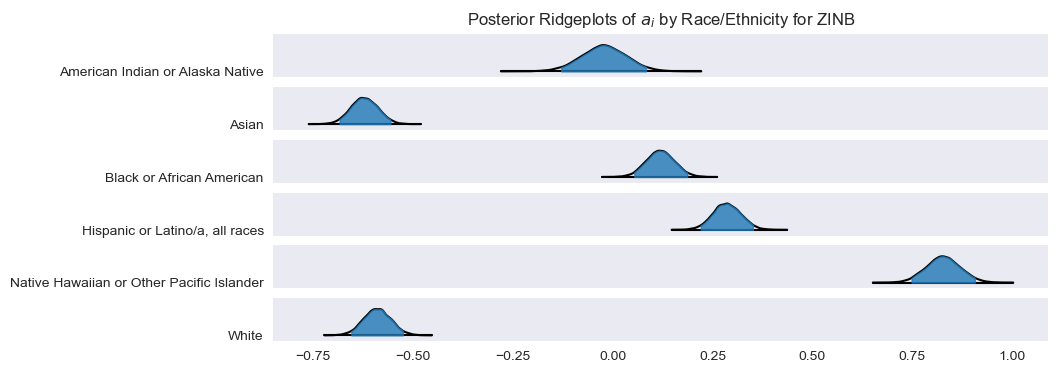

In [64]:
fig, axes = plt.subplots(nrows=num_groups, ncols=1, figsize=(10, 4), sharex=True)

for i, group in enumerate(groups):
    az.plot_forest(
        trace2,
        var_names=["a"],
        coords={"group": [group]},
        kind="ridgeplot",
        ridgeplot_truncate=False,
        ridgeplot_alpha=0.8,
        combined=True,
        ax=axes[i],
        labeller=azl.MapLabeller(var_name_map={"a": group})
    )

axes[0].set_title(r"Posterior Ridgeplots of $a_i$ by Race/Ethnicity for ZINB")
plt.show()

In [65]:
with pm.Model(coords=coords) as m3:
    group_idx_data = pm.Data("group_idx", group_idx, dims="obs")
    week_idx_data = pm.Data("week_idx", week_idx, dims="obs")
    pop_data = pm.Data("population", pop_scaled, dims="obs")
    y_data = pm.Data("y", y, dims="obs")

    # Priors
    sigma_a = pm.HalfNormal("sigma_a", sigma=1.0)
    sigma_f = pm.HalfNormal("sigma_f", sigma=1.0)
    a = pm.ZeroSumNormal("a", sigma=sigma_a, dims="group")
    f = pm.GaussianRandomWalk("f", sigma=sigma_f, dims="week")

    # Linear predictor
    log_mu = a[group_idx_data] + f[week_idx_data]
    mu = pm.Deterministic("mu", pop_data * pm.math.exp(log_mu), dims="obs")

    contrasts(a, coords["group"])

    # Likelihood
    y_obs = pm.Poisson("y_obs", mu=mu, observed=y_data)
    trace3 = pm.sample(5000, tune=1000, target_accept=0.90)
    ppc = pm.sample_posterior_predictive(trace3)
    pm.compute_log_likelihood(trace3)

/Users/keithhall/miniforge3/envs/pymc-env/lib/python3.12/site-packages/pymc/distributions/timeseries.py:290: UserWarning: Initial distribution not specified, defaulting to `Normal.dist(0, 100)`.You can specify an init_dist manually to suppress this warning.
  warnings.warn(
Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [sigma_a, sigma_f, a, f]


Output()

Sampling 4 chains for 1_000 tune and 5_000 draw iterations (4_000 + 20_000 draws total) took 11 seconds.
Sampling: [y_obs]


Output()

Output()

In [66]:
az.summary(trace3, var_names=["a", "f"], filter_vars="like")

,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
f[2020-09],1.059,0.256,0.565,1.520,0.002,0.002,29108.0,15101.0,1.0
f[2020-10],1.884,0.171,1.558,2.198,0.001,0.001,22287.0,14423.0,1.0
f[2020-11],3.515,0.082,3.361,3.669,0.000,0.001,28917.0,15018.0,1.0
f[2020-12],3.840,0.071,3.704,3.970,0.000,0.001,26188.0,14399.0,1.0
f[2020-13],3.880,0.068,3.753,4.008,0.000,0.001,21065.0,14028.0,1.0
...,...,...,...,...,...,...,...,...,...
a[Black or African American] - a[Native Hawaiian or Other Pacific Islander],-0.761,0.025,-0.809,-0.714,0.000,0.000,9972.0,11896.0,1.0
a[Black or African American] - a[White],0.660,0.010,0.642,0.680,0.000,0.000,35238.0,15263.0,1.0
"a[Hispanic or Latino/a, all races] - a[Native Hawaiian or Other Pacific Islander]",-0.603,0.024,-0.649,-0.558,0.000,0.000,8127.0,11049.0,1.0
"a[Hispanic or Latino/a, all races] - a[White]",0.818,0.007,0.806,0.830,0.000,0.000,38774.0,16417.0,1.0


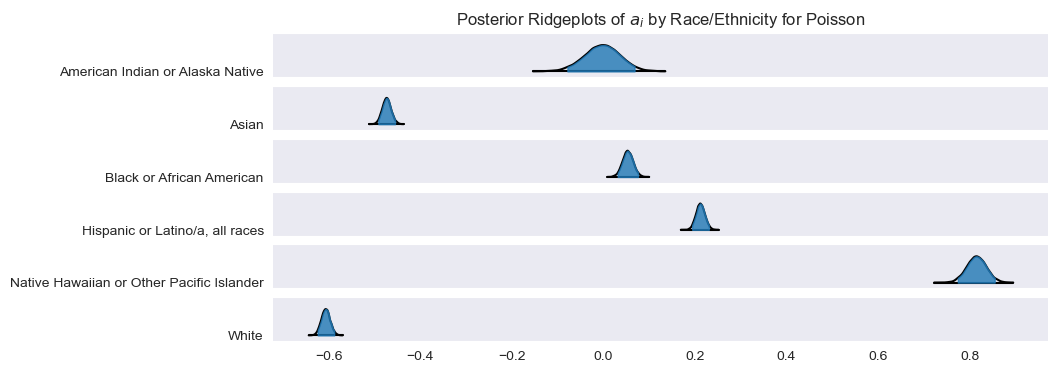

In [67]:
fig, axes = plt.subplots(nrows=num_groups, ncols=1, figsize=(10, 4), sharex=True)

for i, group in enumerate(groups):
    az.plot_forest(
        trace3,
        var_names=["a"],
        coords={"group": [group]},
        kind="ridgeplot",
        ridgeplot_truncate=False,
        ridgeplot_alpha=0.8,
        combined=True,
        ax=axes[i],
        labeller=azl.MapLabeller(var_name_map={"a": group})
    )

axes[0].set_title(r"Posterior Ridgeplots of $a_i$ by Race/Ethnicity for Poisson")
plt.show()

/Users/keithhall/miniforge3/envs/pymc-env/lib/python3.12/site-packages/arviz/stats/stats.py:797: UserWarning: Estimated shape parameter of Pareto distribution is greater than 0.70 for one or more samples. You should consider using a more robust model, this is because importance sampling is less likely to work well if the marginal posterior and LOO posterior are very different. This is more likely to happen with a non-robust model and highly influential observations.
  warnings.warn(
/Users/keithhall/miniforge3/envs/pymc-env/lib/python3.12/site-packages/arviz/stats/stats.py:797: UserWarning: Estimated shape parameter of Pareto distribution is greater than 0.70 for one or more samples. You should consider using a more robust model, this is because importance sampling is less likely to work well if the marginal posterior and LOO posterior are very different. This is more likely to happen with a non-robust model and highly influential observations.
  warnings.warn(
/Users/keithhall/minifor

<Axes: title={'center': 'Model comparison\nlower is better'}, xlabel='elpd_loo (deviance)', ylabel='ranked models'>

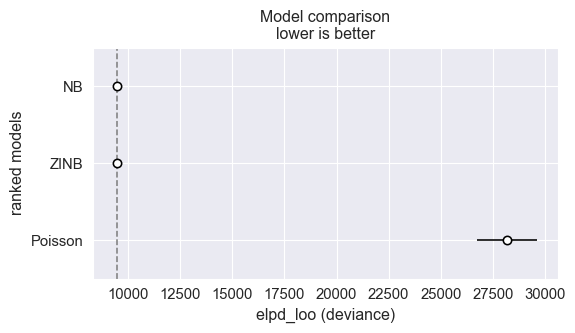

In [68]:
loo_compare = az.compare({"NB": trace, "ZINB": trace2, "Poisson": trace3},
           ic='loo',
           scale='deviance')
az.plot_compare(loo_compare)

/Users/keithhall/miniforge3/envs/pymc-env/lib/python3.12/site-packages/arviz/stats/stats.py:797: UserWarning: Estimated shape parameter of Pareto distribution is greater than 0.70 for one or more samples. You should consider using a more robust model, this is because importance sampling is less likely to work well if the marginal posterior and LOO posterior are very different. This is more likely to happen with a non-robust model and highly influential observations.
  warnings.warn(
/Users/keithhall/miniforge3/envs/pymc-env/lib/python3.12/site-packages/arviz/stats/stats.py:797: UserWarning: Estimated shape parameter of Pareto distribution is greater than 0.70 for one or more samples. You should consider using a more robust model, this is because importance sampling is less likely to work well if the marginal posterior and LOO posterior are very different. This is more likely to happen with a non-robust model and highly influential observations.
  warnings.warn(


<Axes: title={'center': 'Model comparison\nlower is better'}, xlabel='elpd_loo (deviance)', ylabel='ranked models'>

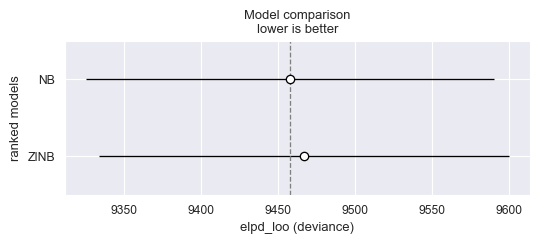

In [69]:
loo_compare = az.compare({"NB": trace, "ZINB": trace2},
           ic='loo',
           scale='deviance')
az.plot_compare(loo_compare)

# Modeling Group Effects Across Eras

In [13]:
def assign_era(week_str):
    year, week = map(int, week_str.split('-'))
    if year == 2020 or (year == 2021 and week <= 15):
        return 0
    elif year == 2021 and 15 < week <= 48:
        return 1
    else:
        return 2

aggregated_data = aggregated_data.reset_index()
aggregated_data["era"] = aggregated_data["year_week"].map(assign_era)
era_idx = aggregated_data["era"].to_numpy()
num_eras = aggregated_data["era"].nunique()
aggregated_data

,characteristic_group,year_week,specimen_collection_date,population_estimate,new_cases,cumulative_cases,new_cases_per_pop,cumulative_cases_per_pop,group_idx,week_idx,era
0,American Indian or Alaska Native,2020-09,2020-03-07,1796.0,0.0,0.0,0.000000,0.000000,0,0,0
1,American Indian or Alaska Native,2020-10,2020-03-14,1796.0,0.0,0.0,0.000000,0.000000,0,1,0
2,American Indian or Alaska Native,2020-11,2020-03-21,1796.0,0.0,0.0,0.000000,0.000000,0,2,0
3,American Indian or Alaska Native,2020-12,2020-03-28,1796.0,0.0,0.0,0.000000,0.000000,0,3,0
4,American Indian or Alaska Native,2020-13,2020-04-04,1796.0,0.0,0.0,0.000000,0.000000,0,4,0
...,...,...,...,...,...,...,...,...,...,...,...
1111,White,2023-32,2023-08-06,348449.0,77.0,48872.0,0.000221,0.140256,5,181,2
1112,White,2023-33,2023-08-13,348449.0,81.0,48950.0,0.000232,0.140480,5,182,2
1113,White,2023-34,2023-08-20,348449.0,92.0,49031.0,0.000264,0.140712,5,183,2
1114,White,2023-35,2023-08-27,348449.0,92.0,49126.0,0.000264,0.140985,5,184,2


In [20]:
def labeled_contrasts(var, name, label, index):
    for i, j in combinations(range(index.size), 2):
        a, b = index[i], index[j]
        pm.Deterministic(f"{name}[{label},{a}] - {name}[{label},{b}]", var[i] - var[j])

In [21]:
coords = {
    "group": groups,
    "era": np.arange(num_eras),
    "obs": np.arange(len(aggregated_data)),
}


with pm.Model(coords=coords) as m4:
    group_idx_data = pm.Data("group_idx", group_idx, dims="obs")
    era_idx_data = pm.Data("era_idx", era_idx, dims="obs")
    pop_data = pm.Data("population", pop_scaled, dims="obs")
    y_data = pm.Data("y", y, dims="obs")

    sigma_a = pm.HalfNormal("sigma_a", sigma=1.0)
    sigma_beta = pm.HalfNormal("sigma_beta", sigma=1.0)
    # sigma_a_beta = pm.HalfNormal("sigma_a_beta", sigma=0.2)
    # sigma_f = pm.HalfNormal("sigma_f", sigma=1.0)

    a = pm.ZeroSumNormal("a", sigma=sigma_a, dims="group")
    beta = pm.ZeroSumNormal("beta", sigma=sigma_beta, dims="era")
    a_beta = pm.Normal("a_beta", mu=0, sigma=0.2, dims=("group", "era"))
    # f = pm.GaussianRandomWalk("f", sigma=1, dims="week")

    phi = pm.HalfNormal("phi", sigma=1.0)

    log_mu = (
        a[group_idx_data] +
        beta[era_idx_data] +
        a_beta[group_idx_data, era_idx_data]
        # f[week_idx_data]
    )
    mu = pm.Deterministic("mu", pop_data * pm.math.exp(log_mu), dims="obs")

    contrasts(a, coords["group"])
    contrasts(beta, coords["era"])
    for group in groups:
        g = group_map[group]
        labeled_contrasts(a_beta[g], a_beta.name, group, coords["era"])

    y_obs = pm.NegativeBinomial("y_obs", mu=mu, alpha=phi, observed=y_data)
    trace4 = pm.sample(5000, tune=1000, target_accept=0.97)
    ppc = pm.sample_posterior_predictive(trace4)
    pm.compute_log_likelihood(trace4)

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [sigma_a, sigma_beta, a, beta, a_beta, phi]


Output()

Sampling 4 chains for 1_000 tune and 5_000 draw iterations (4_000 + 20_000 draws total) took 31 seconds.
Sampling: [y_obs]


Output()

Output()

In [27]:
az.summary(trace4, var_names=["a", "beta"], filter_vars="like", kind="stats", round_to=4)

,mean,sd,hdi_3%,hdi_97%
"a_beta[American Indian or Alaska Native, 0]",2.1595,0.1697,1.8362,2.4755
"a_beta[American Indian or Alaska Native, 1]",1.8898,0.1783,1.5588,2.2286
"a_beta[American Indian or Alaska Native, 2]",2.6578,0.1656,2.3406,2.9642
"a_beta[Asian, 0]",2.1393,0.1571,1.8602,2.4520
"a_beta[Asian, 1]",2.1420,0.1563,1.8574,2.4443
...,...,...,...,...
"a_beta[Native Hawaiian or Other Pacific Islander,0] - a_beta[Native Hawaiian or Other Pacific Islander,2]",0.1388,0.1834,-0.2198,0.4736
"a_beta[Native Hawaiian or Other Pacific Islander,1] - a_beta[Native Hawaiian or Other Pacific Islander,2]",0.1073,0.1889,-0.2433,0.4661
"a_beta[White,0] - a_beta[White,1]",-0.3421,0.1837,-0.6924,-0.0006
"a_beta[White,0] - a_beta[White,2]",-0.0913,0.1814,-0.4375,0.2398


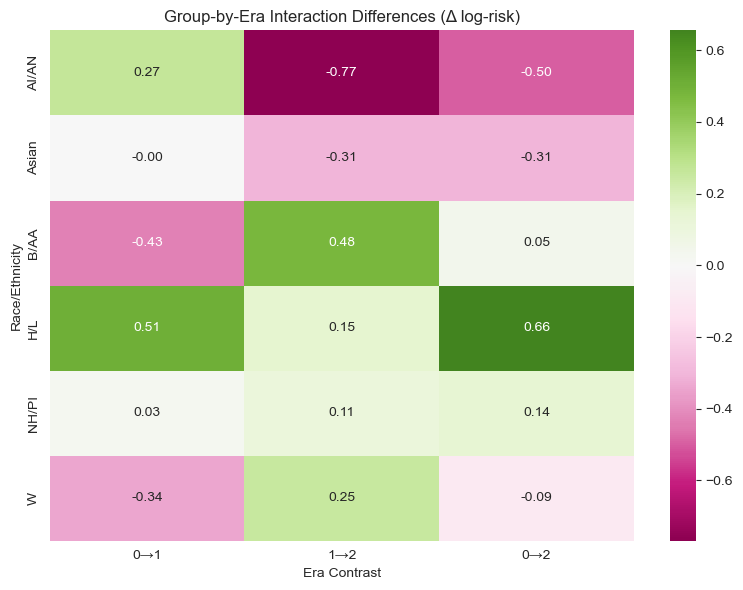

In [34]:
era_diff_df = pd.DataFrame({
    "0→1": {
        "AI/AN": 0.270,
        "Asian": -0.003,
        "B/AA": -0.431,
        "H/L": 0.505,
        "NH/PI": 0.032,
        "W": -0.342
    },
    "1→2": {
        "AI/AN": -0.768,
        "Asian": -0.307,
        "B/AA": 0.477,
        "H/L": 0.150,
        "NH/PI": 0.107,
        "W": 0.251
    },
    "0→2": {
        "AI/AN": -0.498,
        "Asian": -0.309,
        "B/AA": 0.046,
        "H/L": 0.655,
        "NH/PI": 0.139,
        "W": -0.091
    }
})

plt.figure(figsize=(8,6))
sns.heatmap(
    era_diff_df,
    cmap="PiYG",
    center=0,
    annot=True,
    fmt=".2f",
    annot_kws={"size": 10}
)

plt.title("Group-by-Era Interaction Differences (Δ log-risk)")
plt.xlabel("Era Contrast")
plt.ylabel("Race/Ethnicity")
plt.tight_layout()
plt.show()